# 15 · Explore signals with NumPy FFT

**Level:** Expert practice · **Practice time:** 30–50 minutes

[← Previous](14_advanced_array_patterns.ipynb) · [Course guide](../README.md) · [Next →](16_project_sales_analysis.ipynb)

**You will learn:** Build a sampled signal, identify frequency peaks, and reconstruct a filtered signal.

**Prerequisites:** Notebooks 00–14; a sine wave repeats at a frequency measured in cycles per second.

## How to learn with this notebook

1. Run cells from top to bottom. Predict results before executing each example.
2. Do the **Try it** experiment by editing the example or adding a cell below it.
3. Replace `None` in each exercise with your answer, then rerun its check cell.
4. Consult the solutions at the end only after trying. An untouched exercise prints **Pending**, so Run All succeeds without claiming you solved it.
5. Complete the independent challenge, then restart the kernel and run all cells again.

Each notebook imports its own dependencies and creates its own data. You do not need variables from another notebook. The supplied outputs show a verified reference run; rerun cells to explore your changes.

In [1]:
import numpy as np
np.set_printoptions(precision=4, suppress=True)
print("NumPy version:", np.__version__)

NumPy version: 2.5.3


## Step 1 · Build a signal with known frequencies

Sampling records a signal at evenly spaced times. A sample rate of fs gives a Nyquist frequency fs/2; frequencies above that limit cannot be uniquely recovered without additional assumptions. We use endpoint=False so a one-second record contains exactly fs samples without repeating the endpoint.

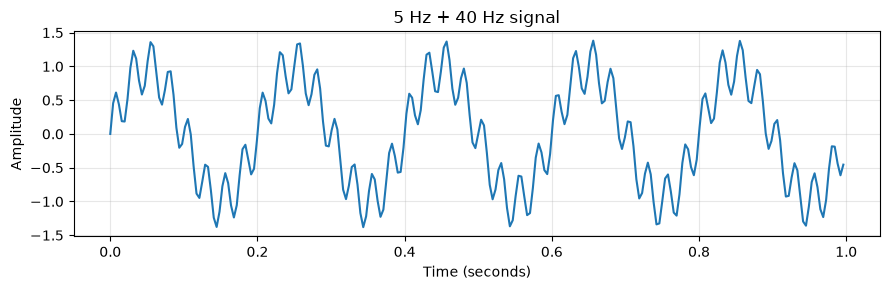

In [2]:
import matplotlib.pyplot as plt
sample_rate = 256
time = np.arange(sample_rate) / sample_rate
signal = np.sin(2 * np.pi * 5 * time) + 0.4 * np.sin(2 * np.pi * 40 * time)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(time, signal)
ax.set(xlabel="Time (seconds)", ylabel="Amplitude", title="5 Hz + 40 Hz signal")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
assert signal.shape == (256,)

**Try it:** Change the 40 Hz amplitude and predict how the signal and spectrum change.

## Step 2 · Transform time into frequency

For a real-valued signal, `rfft` returns the nonnegative-frequency coefficients. `rfftfreq` provides their frequencies. The frequency-bin spacing is fs/N. Our one-second example uses whole cycles, reducing boundary discontinuities. Non-integer cycles cause spectral leakage; windowing is a useful extension.

Peak frequencies: [ 5. 40.]
Peak amplitudes: [1.  0.4]


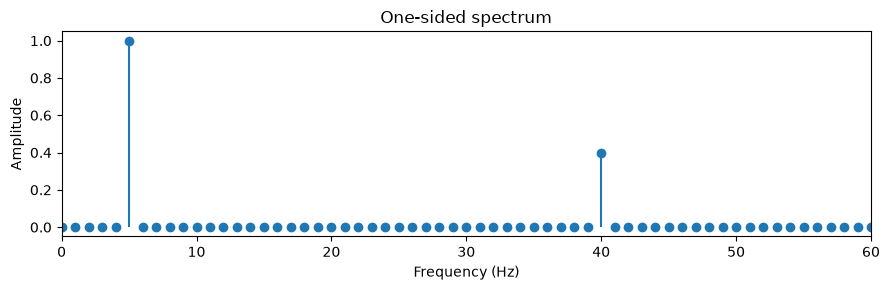

In [3]:
spectrum = np.fft.rfft(signal)
frequencies = np.fft.rfftfreq(signal.size, d=1 / sample_rate)
amplitude = np.abs(spectrum) / signal.size
# Double only bins that have negative-frequency partners: this N is even.
amplitude[1:-1] *= 2
peak_indices = np.argsort(amplitude)[-2:][::-1]
print("Peak frequencies:", frequencies[peak_indices])
print("Peak amplitudes:", amplitude[peak_indices])
np.testing.assert_allclose(frequencies[peak_indices], [5, 40])
fig, ax = plt.subplots(figsize=(9, 3))
ax.stem(frequencies, amplitude, basefmt=" ")
ax.set(xlim=(0, 60), xlabel="Frequency (Hz)", ylabel="Amplitude", title="One-sided spectrum")
plt.tight_layout()
plt.show()

**Try it:** Use 5.5 Hz instead of 5 Hz and inspect the leakage into nearby bins.

## Step 3 · Filter and reconstruct

Here we zero coefficients above 10 Hz and invert the FFT. This is a learning example of an ideal frequency cutoff. Abrupt cutoffs can create ringing for other signals; real filtering design also considers boundaries and transient behavior. Passing n preserves the intended length, including for odd-length signals.

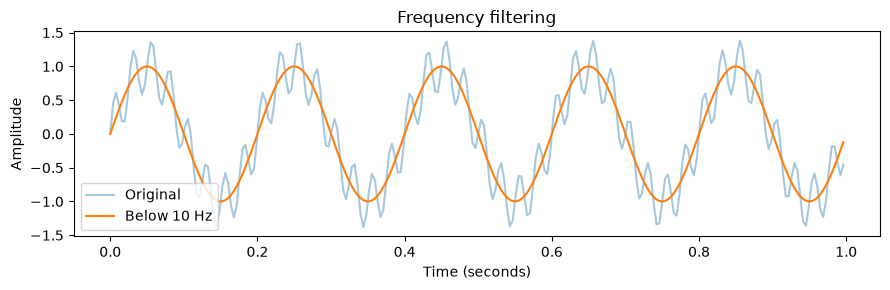

In [4]:
filtered_spectrum = spectrum.copy()
filtered_spectrum[frequencies > 10] = 0
filtered = np.fft.irfft(filtered_spectrum, n=signal.size)
expected = np.sin(2 * np.pi * 5 * time)
np.testing.assert_allclose(filtered, expected, atol=1e-12)
np.testing.assert_allclose(np.fft.irfft(spectrum, n=signal.size), signal, atol=1e-12)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(time, signal, alpha=0.4, label="Original")
ax.plot(time, filtered, label="Below 10 Hz")
ax.set(xlabel="Time (seconds)", ylabel="Amplitude", title="Frequency filtering")
ax.legend()
plt.tight_layout()
plt.show()

**Try it:** Set the cutoff to 50 Hz and check that the original signal is recovered.

## Your practice exercises

Use the named answer variables. The checks verify your result; they do not require the same approach as the reference solution. If an assertion fails, read the expected value and inspect your shape and dtype.

### Exercise 1

Find the dominant frequency in this 8 Hz signal, sampled at 100 Hz.

In [5]:
fs = 100
t = np.arange(100) / fs
wave = np.sin(2 * np.pi * 8 * t)

dominant_hz = None  # TODO: replace None with your answer

In [6]:
if dominant_hz is None:
    print("Pending: complete Exercise 1 first.")
else:
    np.testing.assert_allclose(dominant_hz, 8)
    print("Exercise 1 passed!")

Pending: complete Exercise 1 first.


### Exercise 2

Reconstruct wave by applying rfft then irfft; preserve its length.

In [7]:
reconstructed = None  # TODO: replace None with your answer

In [8]:
if reconstructed is None:
    print("Pending: complete Exercise 2 first.")
else:
    assert reconstructed.shape == wave.shape
    np.testing.assert_allclose(reconstructed, wave, atol=1e-12)
    print("Exercise 2 passed!")

Pending: complete Exercise 2 first.


## Independent challenge

Add seeded Gaussian noise to a sine wave. Compare reconstruction RMSE before and after a frequency cutoff. Explain why an appropriate cutoff depends on the signal.

Add code and explanation cells below. Decide on expected results before checking your implementation.

In [9]:
# Your independent challenge work goes here.

## Before you move on

- Explain the main idea in your own words without reading the examples.
- Make both exercise checks print **passed**.
- Try at least one changed input or edge case and explain the result.
- Finish the independent challenge or write down a specific question to revisit.

Expertise comes from repeated practice and debugging unfamiliar problems. Completing these notebooks gives you a broad practical foundation, not a substitute for that experience.

---

## Reference solutions — try first

These cells use separate reference variables, so they do not fill in your exercise answers. They also check the reference result. Compare your reasoning as well as the output.

### Solution 1

Find the dominant frequency in this 8 Hz signal, sampled at 100 Hz.

**Why it works:** Find the largest magnitude FFT coefficient, then look up its matching frequency using the actual sample interval.

In [10]:
reference_dominant_hz = np.fft.rfftfreq(wave.size, d=1/fs)[np.abs(np.fft.rfft(wave)).argmax()]
np.testing.assert_allclose(reference_dominant_hz, 8)
print(reference_dominant_hz)

8.0


### Solution 2

Reconstruct wave by applying rfft then irfft; preserve its length.

**Why it works:** The forward and inverse real transforms round-trip the signal; n explicitly preserves the original sample count.

In [11]:
reference_reconstructed = np.fft.irfft(np.fft.rfft(wave), n=wave.size)
assert reference_reconstructed.shape == wave.shape
np.testing.assert_allclose(reference_reconstructed, wave, atol=1e-12)
print(reference_reconstructed)

[ 0.      0.4818  0.8443  0.998   0.9048  0.5878  0.1253 -0.3681 -0.7705
 -0.9823 -0.9511 -0.6845 -0.2487  0.2487  0.6845  0.9511  0.9823  0.7705
  0.3681 -0.1253 -0.5878 -0.9048 -0.998  -0.8443 -0.4818 -0.      0.4818
  0.8443  0.998   0.9048  0.5878  0.1253 -0.3681 -0.7705 -0.9823 -0.9511
 -0.6845 -0.2487  0.2487  0.6845  0.9511  0.9823  0.7705  0.3681 -0.1253
 -0.5878 -0.9048 -0.998  -0.8443 -0.4818 -0.      0.4818  0.8443  0.998
  0.9048  0.5878  0.1253 -0.3681 -0.7705 -0.9823 -0.9511 -0.6845 -0.2487
  0.2487  0.6845  0.9511  0.9823  0.7705  0.3681 -0.1253 -0.5878 -0.9048
 -0.998  -0.8443 -0.4818 -0.      0.4818  0.8443  0.998   0.9048  0.5878
  0.1253 -0.3681 -0.7705 -0.9823 -0.9511 -0.6845 -0.2487  0.2487  0.6845
  0.9511  0.9823  0.7705  0.3681 -0.1253 -0.5878 -0.9048 -0.998  -0.8443
 -0.4818]


## Continue learning

- [Official NumPy documentation: routines.fft ](https://numpy.org/doc/stable/reference/routines.fft.html)

[Next →](16_project_sales_analysis.ipynb)